In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy.optimize import minimize


In [9]:
assets = {
    "SPY": "US Equities",
    "EFA": "International Equities",
    "IEF": "US Bonds",
    "GLD": "Gold",
    "VNQ": "Real Estate"
}

tickers = list(assets.keys())

prices = yf.download(
    tickers,
    start="2019-01-01",
    end="2026-01-01",
    auto_adjust=True
)["Close"]

prices.head()

[*********************100%***********************]  5 of 5 completed


Ticker,EFA,GLD,IEF,SPY,VNQ
Date,,,,,
2019-01-02,46.729977,121.330002,86.240944,223.251556,54.565182
2019-01-03,46.307766,122.430000,86.926453,217.924179,54.946651
2019-01-04,47.725758,121.440002,86.224426,225.223694,55.589905
2019-01-07,47.908978,121.860001,85.984917,226.999496,56.135944
2019-01-08,48.219654,121.529999,85.770172,229.132248,57.295307


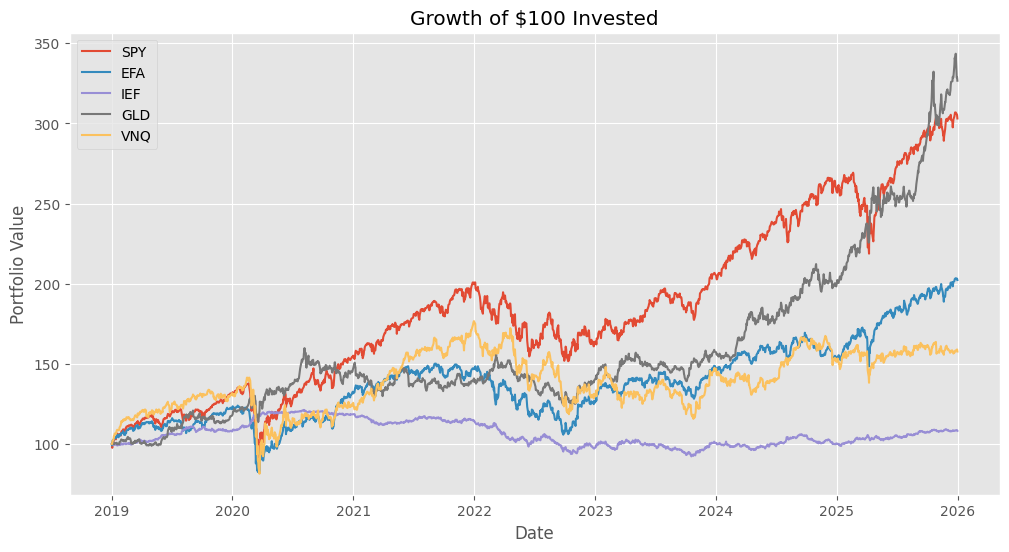

In [ ]:
normalized_prices = prices / prices.iloc[0] * 100 
# by doing this we are comparing the result of a investment if we have invested 100$ at the first day rather than just comparing stock prices

plt.figure(figsize=(12, 6))

for ticker in tickers:
    plt.plot(
        normalized_prices.index,
        normalized_prices[ticker],
        label=ticker
    )

plt.title("Growth of $100 Invested")
plt.xlabel("Date")
plt.ylabel("Portfolio Value")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
returns = prices.pct_change().dropna()
# percentage change of on trading day to another
returns.head()

Ticker,EFA,GLD,IEF,SPY,VNQ
Date,,,,,
2019-01-03,-0.009035,0.009066,0.007949,-0.023863,0.006991
2019-01-04,0.030621,-0.008086,-0.008076,0.033496,0.011707
2019-01-07,0.003839,0.003458,-0.002778,0.007885,0.009823
2019-01-08,0.006485,-0.002708,-0.002497,0.009395,0.020653
2019-01-09,0.011234,0.006418,0.000578,0.004674,-0.001436


In [ ]:
annual_returns = returns.mean() * 252
# 252 trading days

annual_returns_pct = annual_returns * 100

annual_returns_pct.sort_values(ascending=False)

annual_returns_pct

Ticker
EFA    11.807625
GLD    18.206336
IEF     1.400968
SPY    17.851769
VNQ     9.195267
dtype: float64

In [ ]:
annual_volatility = returns.std() * np.sqrt(252)
# Because volatility scales approximately with the square root of time

annual_volatility_pct = annual_volatility * 100

annual_volatility_pct.sort_values(ascending=False)

Ticker
VNQ    22.965448
SPY    19.781382
EFA    18.447096
GLD    15.756129
IEF     7.342115
dtype: float64

In [25]:
performance = pd.DataFrame({
    "Annual Return": annual_returns,
    "Annual Volatility": annual_volatility
})

performance["Return (%)"] = performance["Annual Return"] * 100
performance["Volatility (%)"] = performance["Annual Volatility"] * 100

performance[["Return (%)", "Volatility (%)"]]

performance

,Annual Return,Annual Volatility,Return (%),Volatility (%)
Ticker,,,,
EFA,0.118076,0.184471,11.807625,18.447096
GLD,0.182063,0.157561,18.206336,15.756129
IEF,0.014010,0.073421,1.400968,7.342115
SPY,0.178518,0.197814,17.851769,19.781382
VNQ,0.091953,0.229654,9.195267,22.965448


In [26]:
correlation_matrix = returns.corr()

correlation_matrix

Ticker,EFA,GLD,IEF,SPY,VNQ
Ticker,,,,,
EFA,1.000000,0.218047,-0.050293,0.857758,0.724404
GLD,0.218047,1.000000,0.332375,0.105339,0.161897
IEF,-0.050293,0.332375,1.000000,-0.106823,0.070042
SPY,0.857758,0.105339,-0.106823,1.000000,0.763123
VNQ,0.724404,0.161897,0.070042,0.763123,1.000000


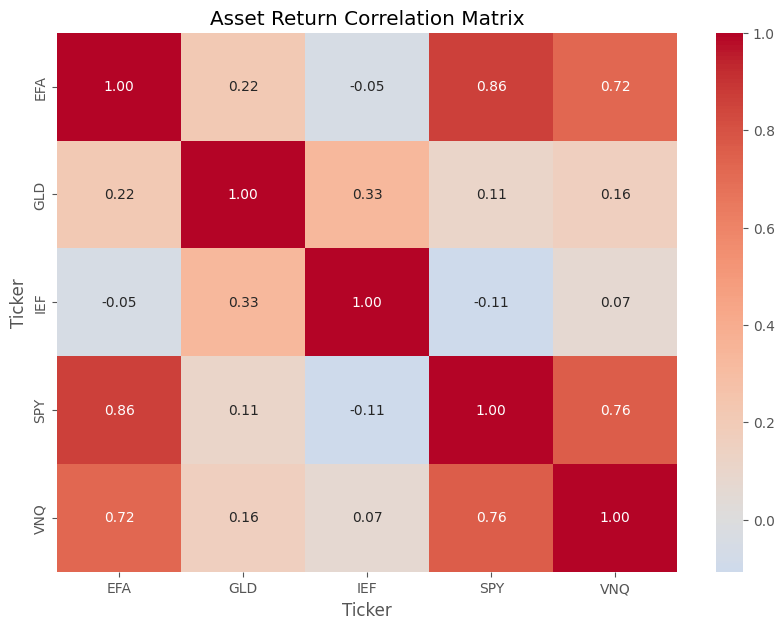

In [27]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Asset Return Correlation Matrix")
plt.show()

In [29]:
sharpe_ratio = annual_returns / annual_volatility

sharpe_ratio.sort_values(ascending=False)

Ticker
GLD    1.155508
SPY    0.902453
EFA    0.640080
VNQ    0.400396
IEF    0.190813
dtype: float64

In [33]:
cumulative = (1 + returns).cumprod()

running_max = cumulative.cummax()

drawdown = cumulative / running_max - 1

max_drawdown = drawdown.min()

max_drawdown_pct = max_drawdown * 100

max_drawdown_pct.sort_values()

Ticker
VNQ   -42.398164
EFA   -33.930079
SPY   -33.717274
IEF   -23.924764
GLD   -22.002168
dtype: float64

In [35]:
# order : SPY EFA IEF GLD VNQ

weights_spy = np.array([1, 0, 0, 0, 0])

weights_60_40 = np.array([0.6, 0.0, 0.4, 0.0, 0.0])

weights_equal = np.array([0.2, 0.2, 0.2, 0.2, 0.2])

In [37]:
portfolio_returns = pd.DataFrame({
    "SPY": returns @ weights_spy,
    "60/40": returns @ weights_60_40,
    "Equal Weight": returns @ weights_equal
})

portfolio_annual_returns = portfolio_returns.mean() * 252

portfolio_annual_returns * 100

SPY             11.807625
60/40            7.644962
Equal Weight    11.692393
dtype: float64

In [38]:
portfolio_volatility = portfolio_returns.std() * np.sqrt(252)

portfolio_sharpe = portfolio_annual_returns / portfolio_volatility

portfolio_performance = pd.DataFrame({
    "Annual Return": portfolio_annual_returns * 100,
    "Annual Volatility": portfolio_volatility * 100,
    "Sharpe Ratio": portfolio_sharpe
})

portfolio_performance

,Annual Return,Annual Volatility,Sharpe Ratio
SPY,11.807625,18.447096,0.640080
60/40,7.644962,11.307599,0.676091
Equal Weight,11.692393,12.425402,0.941007


In [39]:
portfolio_cumulative = (1 + portfolio_returns).cumprod()

portfolio_running_max = portfolio_cumulative.cummax()

portfolio_drawdown = (
    portfolio_cumulative / portfolio_running_max - 1
)

portfolio_max_drawdown = portfolio_drawdown.min()

portfolio_max_drawdown * 100

SPY            -33.930079
60/40          -24.682813
Equal Weight   -22.600154
dtype: float64

In [40]:
def portfolio_return(weights, returns):
    return np.sum(weights * returns.mean()) * 252


def portfolio_volatility(weights, returns):
    covariance_matrix = returns.cov() * 252
    return np.sqrt(
        weights.T @ covariance_matrix @ weights
    )


def portfolio_sharpe(weights, returns):
    return (
        portfolio_return(weights, returns)
        / portfolio_volatility(weights, returns)
    )

In [42]:
initial_weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
constraints = ({
    "type": "eq",
    "fun": lambda weights: np.sum(weights) - 1
})

bounds = tuple(
    (0, 1) for _ in range(len(tickers))
)

In [44]:
result = minimize(
    lambda weights: -portfolio_sharpe(weights, returns),
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

optimized_weights = result.x

optimized_weights

array([4.75424775e-17, 6.30381116e-01, 0.00000000e+00, 3.69618884e-01,
       0.00000000e+00])

In [45]:
optimized_return = portfolio_return(
    optimized_weights,
    returns
)

optimized_volatility = portfolio_volatility(
    optimized_weights,
    returns
)

optimized_sharpe = portfolio_sharpe(
    optimized_weights,
    returns
)

optimized_return_pct = optimized_return * 100
optimized_volatility_pct = optimized_volatility * 100

print("Annual Return:", optimized_return_pct)
print("Annual Volatility:", optimized_volatility_pct)
print("Sharpe Ratio:", optimized_sharpe)

Annual Return: 18.075281318017204
Annual Volatility: 12.93872649237507
Sharpe Ratio: 1.3969907570632367


In [46]:
bounds = tuple(
    (0, 0.40) for _ in range(len(tickers))
)

result_constrained = minimize(
    lambda weights: -portfolio_sharpe(weights, returns),
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

constrained_weights = result_constrained.x

constrained_weights

array([0.        , 0.4       , 0.24427641, 0.35572359, 0.        ])

In [47]:
constrained_return = portfolio_return(
    constrained_weights,
    returns
)

constrained_volatility = portfolio_volatility(
    constrained_weights,
    returns
)

constrained_sharpe = portfolio_sharpe(
    constrained_weights,
    returns
)

print("Annual Return:", constrained_return * 100)
print("Annual Volatility:", constrained_volatility * 100)
print("Sharpe Ratio:", constrained_sharpe)

Annual Return: 13.975053149918557
Annual Volatility: 10.32539058386601
Sharpe Ratio: 1.3534648434273608


In [48]:
num_portfolios = 5000

results = []

for _ in range(num_portfolios):

    weights = np.random.random(len(tickers))
    weights = weights / np.sum(weights)

    portfolio_ret = portfolio_return(weights, returns)
    portfolio_vol = portfolio_volatility(weights, returns)
    portfolio_sr = portfolio_ret / portfolio_vol

    results.append([
        portfolio_ret,
        portfolio_vol,
        portfolio_sr
    ])

results = np.array(results)

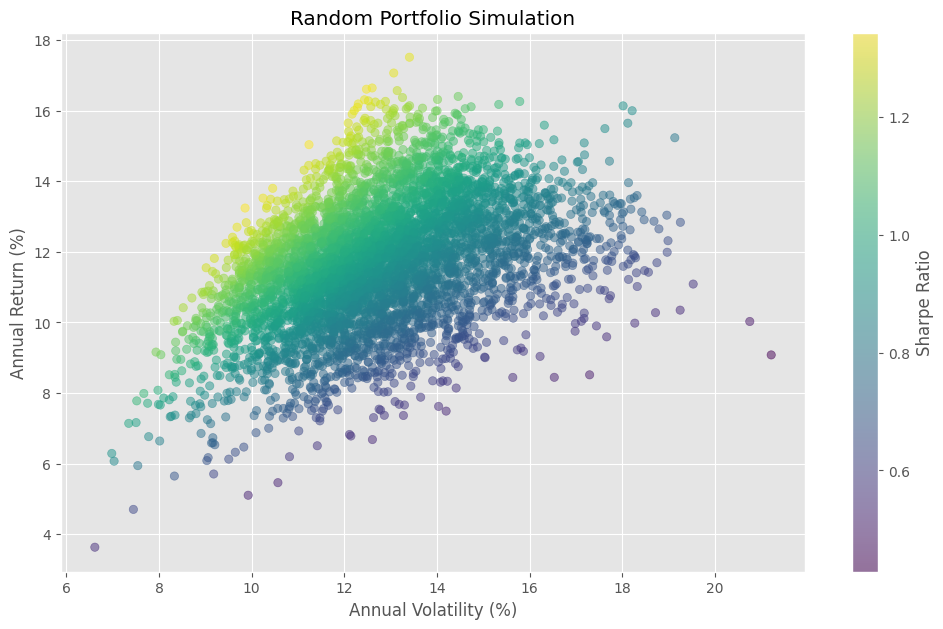

In [49]:
plt.figure(figsize=(12, 7))

plt.scatter(
    results[:, 1] * 100,
    results[:, 0] * 100,
    c=results[:, 2],
    cmap="viridis",
    alpha=0.5
)

plt.xlabel("Annual Volatility (%)")
plt.ylabel("Annual Return (%)")
plt.title("Random Portfolio Simulation")
plt.colorbar(label="Sharpe Ratio")

plt.show()

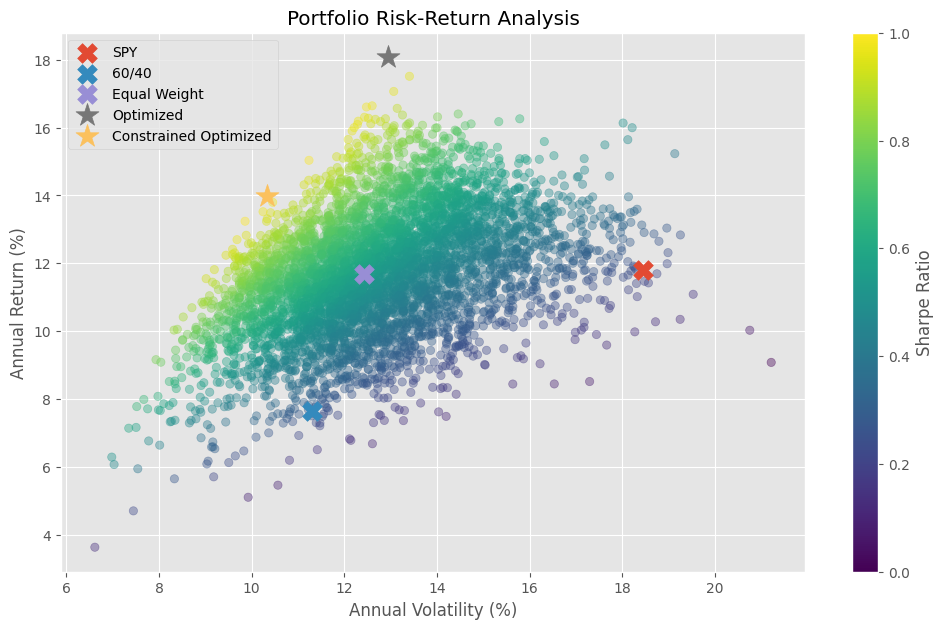

In [51]:
# Calculate portfolio metrics again

spy_return = portfolio_annual_returns["SPY"]
spy_volatility = portfolio_returns["SPY"].std() * np.sqrt(252)

sixty_forty_return = portfolio_annual_returns["60/40"]
sixty_forty_volatility = portfolio_returns["60/40"].std() * np.sqrt(252)

equal_return = portfolio_annual_returns["Equal Weight"]
equal_volatility = portfolio_returns["Equal Weight"].std() * np.sqrt(252)


# Create the plot

plt.figure(figsize=(12, 7))

plt.scatter(
    results[:, 1] * 100,
    results[:, 0] * 100,
    c=results[:, 2],
    cmap="viridis",
    alpha=0.4
)


# SPY
plt.scatter(
    spy_volatility * 100,
    spy_return * 100,
    marker="X",
    s=200,
    label="SPY"
)


# 60/40
plt.scatter(
    sixty_forty_volatility * 100,
    sixty_forty_return * 100,
    marker="X",
    s=200,
    label="60/40"
)


# Equal Weight
plt.scatter(
    equal_volatility * 100,
    equal_return * 100,
    marker="X",
    s=200,
    label="Equal Weight"
)


# Unconstrained optimized
plt.scatter(
    optimized_volatility * 100,
    optimized_return * 100,
    marker="*",
    s=300,
    label="Optimized"
)


# 40% constrained optimized
plt.scatter(
    constrained_volatility * 100,
    constrained_return * 100,
    marker="*",
    s=300,
    label="Constrained Optimized"
)


plt.xlabel("Annual Volatility (%)")
plt.ylabel("Annual Return (%)")
plt.title("Portfolio Risk-Return Analysis")
plt.colorbar(label="Sharpe Ratio")
plt.legend()
plt.grid(True)

plt.show()

In [52]:
# Split the data into training and testing periods

train_prices = prices.loc["2019-01-01":"2023-12-31"]
test_prices = prices.loc["2024-01-01":"2025-12-31"]

train_returns = train_prices.pct_change().dropna()
test_returns = test_prices.pct_change().dropna()

print("Training period:", train_returns.index.min(), "to", train_returns.index.max())
print("Testing period:", test_returns.index.min(), "to", test_returns.index.max())

Training period: 2019-01-03 00:00:00 to 2023-12-29 00:00:00
Testing period: 2024-01-03 00:00:00 to 2025-12-31 00:00:00


In [53]:

train_initial_weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])

train_constraints = ({
    "type": "eq",
    "fun": lambda weights: np.sum(weights) - 1
})

train_bounds = tuple((0, 0.40) for _ in range(len(tickers)))

train_result = minimize(
    lambda weights: -portfolio_sharpe(weights, train_returns),
    train_initial_weights,
    method="SLSQP",
    bounds=train_bounds,
    constraints=train_constraints
)

train_optimized_weights = train_result.x

print("Optimized weights:")
for ticker, weight in zip(tickers, train_optimized_weights):
    print(f"{ticker}: {weight:.2%}")

Optimized weights:
SPY: 0.00%
EFA: 40.00%
IEF: 20.00%
GLD: 40.00%
VNQ: 0.00%


In [54]:

test_portfolio_returns = test_returns @ train_optimized_weights

# Calculate test-period performance

test_annual_return = test_portfolio_returns.mean() * 252
test_annual_volatility = test_portfolio_returns.std() * np.sqrt(252)
test_sharpe = test_annual_return / test_annual_volatility

print(f"Test Annual Return: {test_annual_return:.2%}")
print(f"Test Annual Volatility: {test_annual_volatility:.2%}")
print(f"Test Sharpe Ratio: {test_sharpe:.2f}")

Test Annual Return: 24.54%
Test Annual Volatility: 10.31%
Test Sharpe Ratio: 2.38


In [55]:

test_portfolio_returns = pd.DataFrame({
    "Optimized": test_returns @ train_optimized_weights,
    "SPY": test_returns @ weights_spy,
    "60/40": test_returns @ weights_60_40,
    "Equal Weight": test_returns @ weights_equal
})

# Calculate annualized metrics

test_annual_returns = test_portfolio_returns.mean() * 252
test_annual_volatility = test_portfolio_returns.std() * np.sqrt(252)
test_sharpe_ratios = test_annual_returns / test_annual_volatility

test_comparison = pd.DataFrame({
    "Annual Return": test_annual_returns * 100,
    "Annual Volatility": test_annual_volatility * 100,
    "Sharpe Ratio": test_sharpe_ratios
})

test_comparison

,Annual Return,Annual Volatility,Sharpe Ratio
Optimized,24.537106,10.312095,2.379449
SPY,17.167076,14.733329,1.165186
60/40,11.878517,9.555419,1.243118
Equal Weight,17.078298,10.096449,1.691515


In [56]:
test_cumulative = (1 + test_portfolio_returns).cumprod()

test_running_max = test_cumulative.cummax()

test_drawdown = test_cumulative / test_running_max - 1

test_max_drawdown = test_drawdown.min() * 100

test_max_drawdown.sort_values()

SPY            -14.053466
60/40           -8.504554
Equal Weight    -8.180849
Optimized       -6.749733
dtype: float64

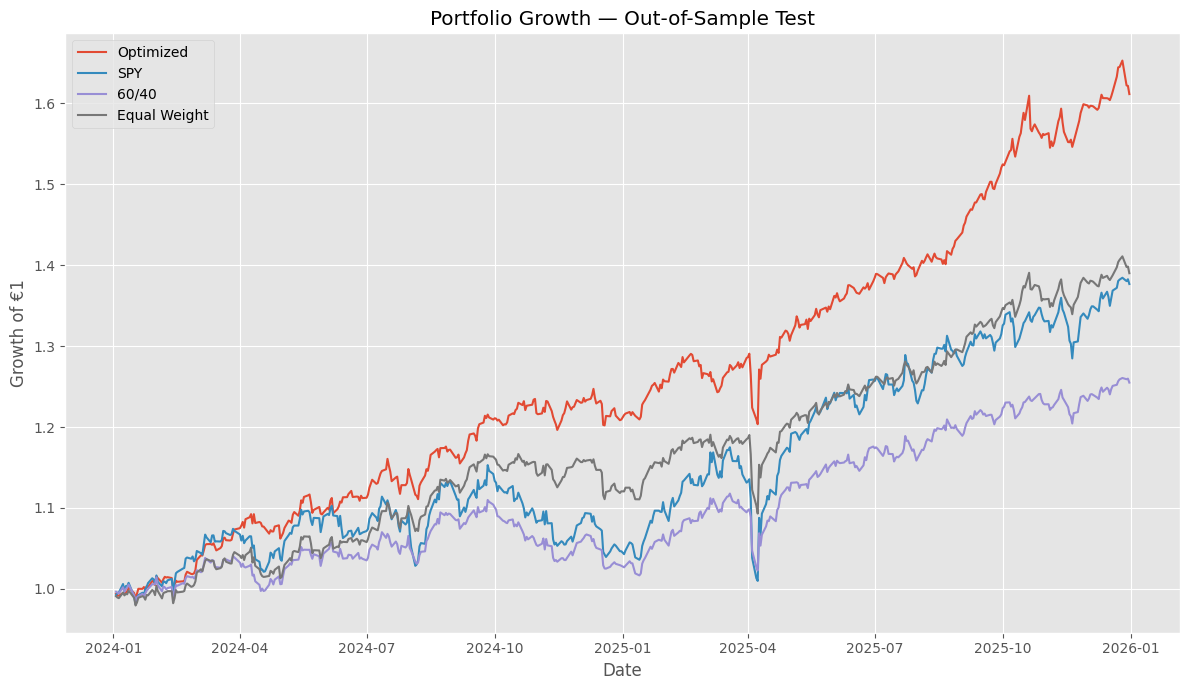

In [ ]:
# 1$ invested
test_cumulative = (1 + test_portfolio_returns).cumprod()


plt.figure(figsize=(12, 7))

for portfolio in test_cumulative.columns:
    plt.plot(
        test_cumulative.index,
        test_cumulative[portfolio],
        label=portfolio
    )

plt.title("Portfolio Growth — Out-of-Sample Test")
plt.xlabel("Date")
plt.ylabel("Growth of €1")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("../figures/out_of_sample_performance.png", dpi=300)
plt.show()

In [58]:
# Calculate cumulative returns for the test period

test_cumulative_returns = (1 + test_portfolio_returns).cumprod() - 1


final_cumulative_returns = test_cumulative_returns.iloc[-1] * 100

final_cumulative_returns.sort_values(ascending=False)

Optimized       61.135856
Equal Weight    39.004063
SPY             37.670252
60/40           25.489482
Name: 2025-12-31 00:00:00, dtype: float64

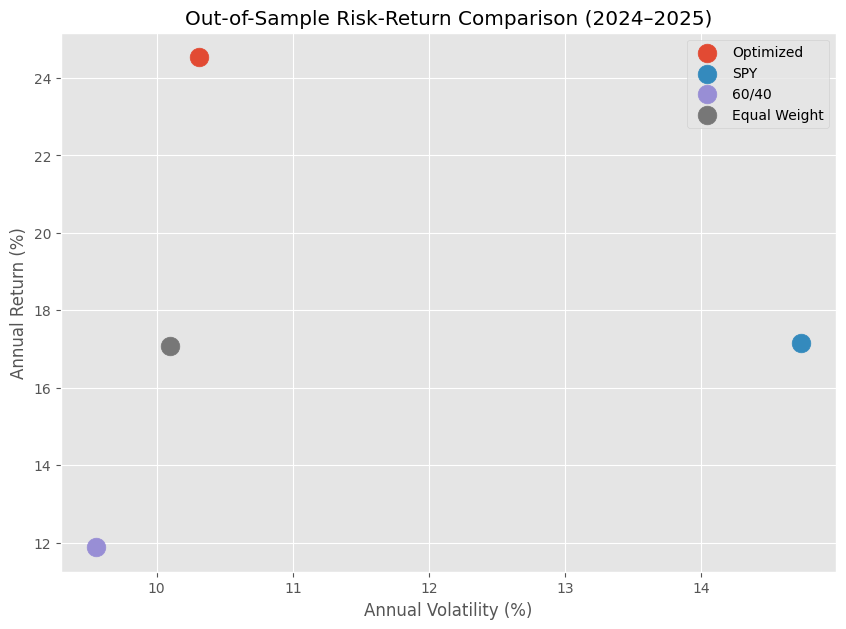

In [66]:

# Final performance comparison

final_metrics = pd.DataFrame({
    "Annual Return": test_annual_returns,
    "Annual Volatility": test_annual_volatility,
    "Sharpe Ratio": test_sharpe_ratios
})

plt.figure(figsize=(10, 7))

for portfolio in final_metrics.index:
    plt.scatter(
        final_metrics.loc[portfolio, "Annual Volatility"] * 100,
        final_metrics.loc[portfolio, "Annual Return"] * 100,
        s=180,
        label=portfolio
    )

plt.xlabel("Annual Volatility (%)")
plt.ylabel("Annual Return (%)")
plt.title("Out-of-Sample Risk-Return Comparison (2024–2025)")
plt.legend()
plt.grid(True)

plt.show()

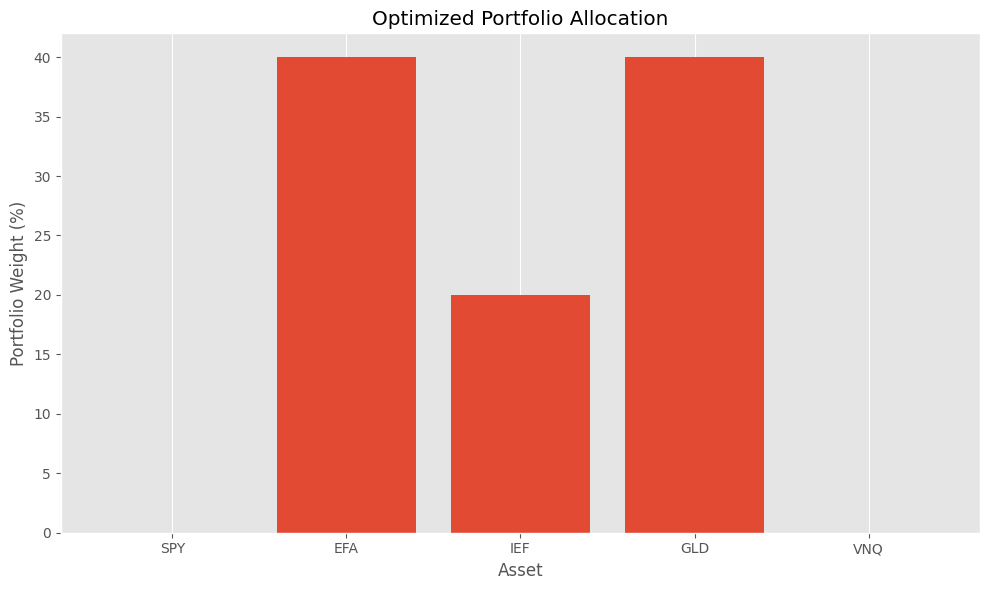

In [65]:
allocation = pd.Series(
    train_optimized_weights,
    index=tickers
)


plt.figure(figsize=(10, 6))

plt.bar(
    allocation.index,
    allocation.values * 100
)

plt.xlabel("Asset")
plt.ylabel("Portfolio Weight (%)")
plt.title("Optimized Portfolio Allocation")
plt.grid(axis="y")

plt.tight_layout()
plt.savefig("../figures/optimized_allocation.png", dpi=300)
plt.show()